# Q2: Are people who know what they want in a partner more successful at finding mutual matches?

I am interested in whether people with more specific priorities for a romantic partner have different rates of mutual matches. The dataset does not directly ask people about deal-breakers or how willing they are to compromise, so I will use the concentration of their stated partner-attribute preferences as an exploratory proxy. This is not a direct measure of strict relational preferences, which is an important limitation.

## Variables
The preference variables are attr1_1 (attractiveness), sinc1_1 (sincerity), intel1_1 (intelligence), fun1_1 (fun), amb1_1 (ambition), and shar1_1 (shared interests). They record how important participants say these attributes are in a partner.
The outcome is match, which indicates whether both people chose each other. iid identifies each participant. Since participants went on multiple dates, I will calculate each person's proportion of dates that resulted in a mutual match.

## Preparation
First, I will inspect the variables and check for missing values. I will remove rows that are missing any of the six preference ratings, the participant ID, or the match outcome. I will divide each preference rating by the sum of the six ratings and add the squared proportions to make a preference-concentration score. Higher scores mean that the stated preferences are concentrated on fewer attributes; lower scores mean the importance is distributed more evenly. I will then group the data by participant and calculate each person's mutual-match rate.

This score is only a proxy for strictness. Someone can care strongly about several qualities without treating them as deal-breakers, and this dataset does not directly measure deal-breakers.

### Load and preview the data

In [2]:
import pandas as pd
df = pd.read_csv("data/speed_dating.csv")
df.shape

(8378, 195)

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
preference_cols = [
    "attr1_1", "sinc1_1", "intel1_1",
    "fun1_1", "amb1_1", "shar1_1"
]

# variables used for this question
df[["iid", "match"] + preference_cols].head()

,iid,match,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1
0,1,0,15.0,20.0,20.0,15.0,15.0,15.0
1,1,0,15.0,20.0,20.0,15.0,15.0,15.0
2,1,1,15.0,20.0,20.0,15.0,15.0,15.0
3,1,1,15.0,20.0,20.0,15.0,15.0,15.0
4,1,1,15.0,20.0,20.0,15.0,15.0,15.0


In [5]:
# Check data types and missing values
df[["iid", "match"] + preference_cols].info()

df[["iid", "match"] + preference_cols].isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   iid       8378 non-null   int64  
 1   match     8378 non-null   int64  
 2   attr1_1   8299 non-null   float64
 3   sinc1_1   8299 non-null   float64
 4   intel1_1  8299 non-null   float64
 5   fun1_1    8289 non-null   float64
 6   amb1_1    8279 non-null   float64
 7   shar1_1   8257 non-null   float64
dtypes: float64(6), int64(2)
memory usage: 523.8 KB


iid           0
match         0
attr1_1      79
sinc1_1      79
intel1_1     79
fun1_1       89
amb1_1       99
shar1_1     121
dtype: int64

In [6]:
# Keep rows with information needed 
analysis_df = df[["iid", "match"] + preference_cols].dropna(
    subset=["iid", "match"] + preference_cols
).copy()

# Remove rows where the six preference ratings sum to zero
preference_totals = analysis_df[preference_cols].sum(axis=1)
analysis_df = analysis_df[preference_totals > 0].copy()

# Convert the ratings to proportions and calculate preference concentration
preference_totals = analysis_df[preference_cols].sum(axis=1)
preference_shares = analysis_df[preference_cols].div(preference_totals, axis=0)
analysis_df["preference_concentration"] = (preference_shares ** 2).sum(axis=1)

# Summarize the repeated dates for each participant
participant_data = analysis_df.groupby("iid").agg(
    preference_concentration=("preference_concentration", "first"),
    match_rate=("match", "mean"),
    number_of_dates=("match", "size")
).reset_index()

print("Number of participants:", len(participant_data))
print("Average mutual-match rate:", participant_data["match_rate"].mean())
participant_data.head()

Number of participants: 541
Average mutual-match rate: 0.1687306823604129


,iid,preference_concentration,match_rate,number_of_dates
0,1,0.170,0.4,10
1,2,0.310,0.2,10
2,3,0.275,0.0,10
3,4,0.180,0.2,10
4,5,0.200,0.2,10


## First-look figure
I will use a scatterplot with a fitted line to compare each participant's preference-concentration score with their mutual-match rate. Each point represents one participant, rather than one date. The fitted line gives an initial view of the relationship, but it cannot show that preferences cause matching success.

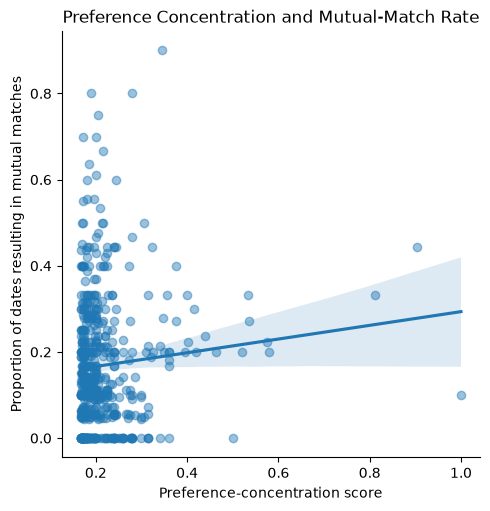

Correlation: 0.084


In [9]:
sns.lmplot(
    data=participant_data,
    x="preference_concentration",
    y="match_rate",
    scatter_kws={"alpha": 0.45}
)

plt.xlabel("Preference-concentration score")
plt.ylabel("Proportion of dates resulting in mutual matches")
plt.title("Preference Concentration and Mutual-Match Rate")
plt.show()

correlation = participant_data[
    ["preference_concentration", "match_rate"]
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 3))

## What I see
The initial relationship is weakly positive. The correlation is about 0.08, which suggests that participants with more concentrated stated preferences may have slightly higher mutual-match rates. The relationship is small, and this score measures how concentrated preferences are rather than directly measuring strict deal-breakers, so this is only an initial observation.

## The plan
For the final analysis, I plan to make a figure that shows how mutual-match success varies across levels of preference concentration. I will use a regression model to test whether preference concentration is associated with mutual-match success, and I will consider whether initial attraction or other variables should be included. Since each participant has multiple interactions, I will account for repeated dates by the same participant where possible.
For the step beyond FDS I, I expect to evaluate the model on held-out data using a train/test split. I will choose a model and performance measure that fit the outcome and compare the predictions with a simple baseline. I will interpret the results as an association, not as proof that strict preferences cause mutual matches.

## Expected outcomes
**If my prediction is right**: I would expect a positive relationship between preference concentration and mutual-match rate. The fitted line would generally slope upward, and the regression coefficient for preference concentration would be positive.

**If my prediction is wrong**: I would expect little or no relationship, with a nearly flat trend and a regression coefficient close to zero. If the relationship is negative, that would suggest that participants with more concentrated preferences have lower mutual-match rates.

Either result would need to be interpreted carefully because preference concentration is not a direct measure of strictness, and factors such as attraction or compatibility could also influence mutual matches.